# 3. Da li model zaista gleda grinju?

Prvi model (BeeImage) imao je tačnost 97%, a nije prepoznavao bolest — prepoznavao je
pozadinu snimka. Zato se za novi model ne prihvata samo tačnost, nego se proverava
**na šta model gleda**, i kako radi na slikama koje nisu iz skupa za trening.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
pd.set_option("display.max_colwidth", 80)

RUNS = ROOT / 'runs'
runs = sorted(p.name for p in RUNS.glob('varroa_*') if (p / 'checks.json').exists())

## 3.1 Test 1 — brisanje grinje

Na svakoj zaraženoj test pčeli koju je model prepoznao, grinja se prekrije bojom
okoline. **Ako model gleda grinju, procena treba da pređe u „zdrava".**

Kontrola: isto toliko mesta se prekrije na drugom delu pčele. Tu procena treba da
ostane „varoa". Razlika između ova dva broja je dokaz.

In [2]:
checks = {r: json.loads((RUNS / r / "checks.json").read_text()) for r in runs}
pd.DataFrame({c["arch_display"]: c["masking"] for c in checks.values()})

,EfficientNetB0,MobileNetV3-Large,ResNet50
zarazenih_test_slika,942.0000,942.0000,942.0000
prepoznato_kao_varoa_original,0.8418,0.8758,0.8684
ostalo_varoa_kad_se_grinja_prekrije,0.0315,0.0352,0.0391
ostalo_varoa_kad_se_prekrije_drugo_mesto,0.9584,0.9770,0.9817
prosecna_p_varoa_original,0.9213,0.9379,0.9253
prosecna_p_varoa_grinja_prekrivena,0.0589,0.0738,0.0642
prosecna_p_varoa_drugo_mesto_prekriveno,0.8937,0.9225,0.9170


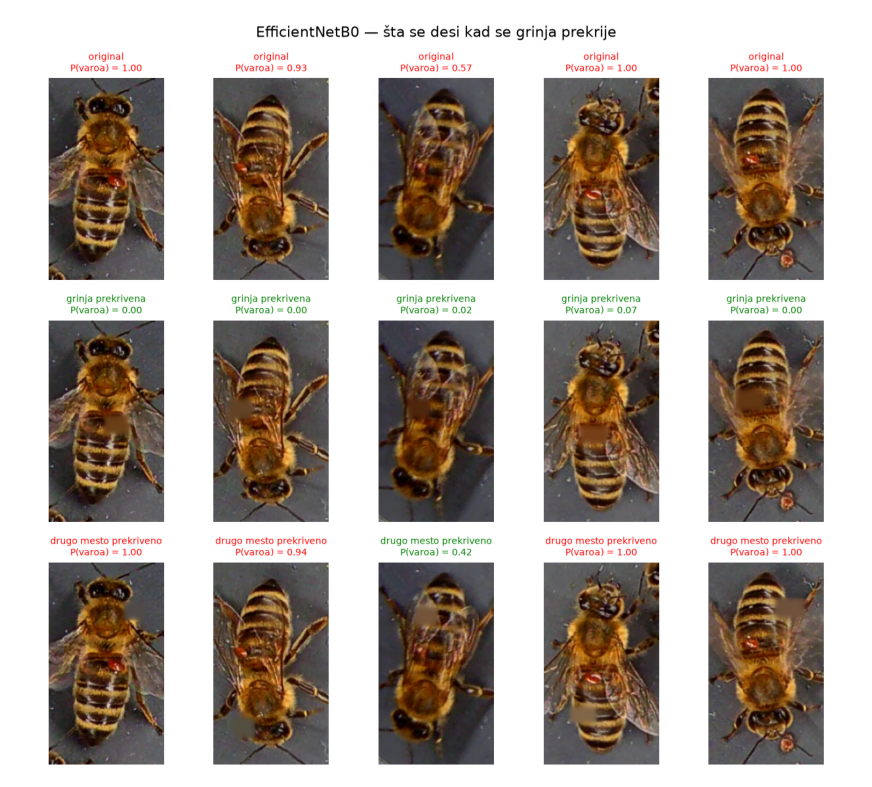

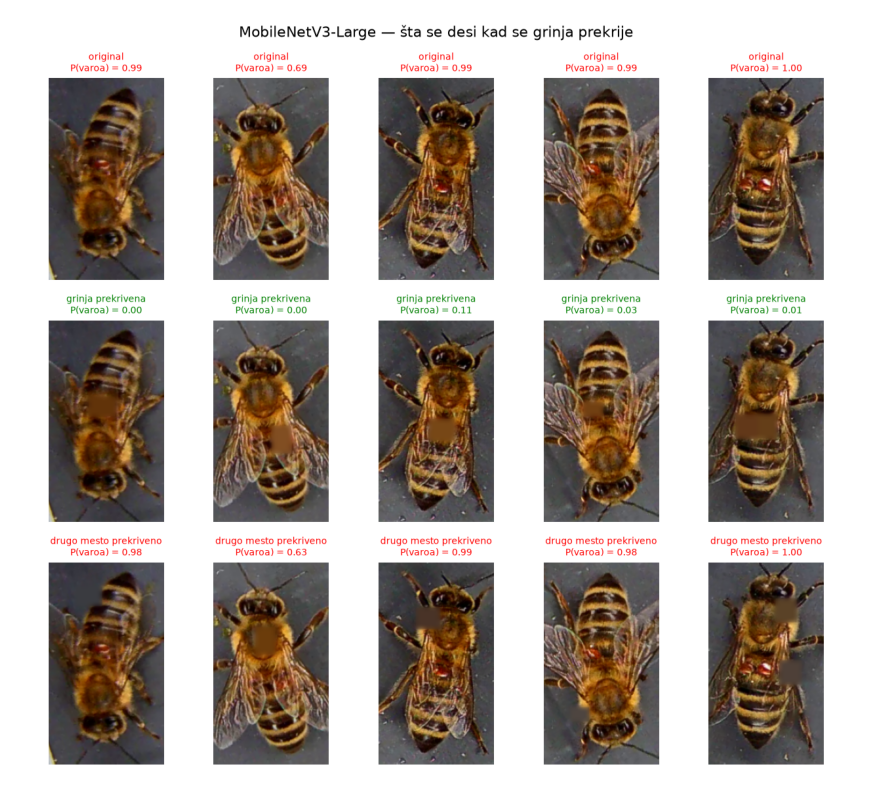

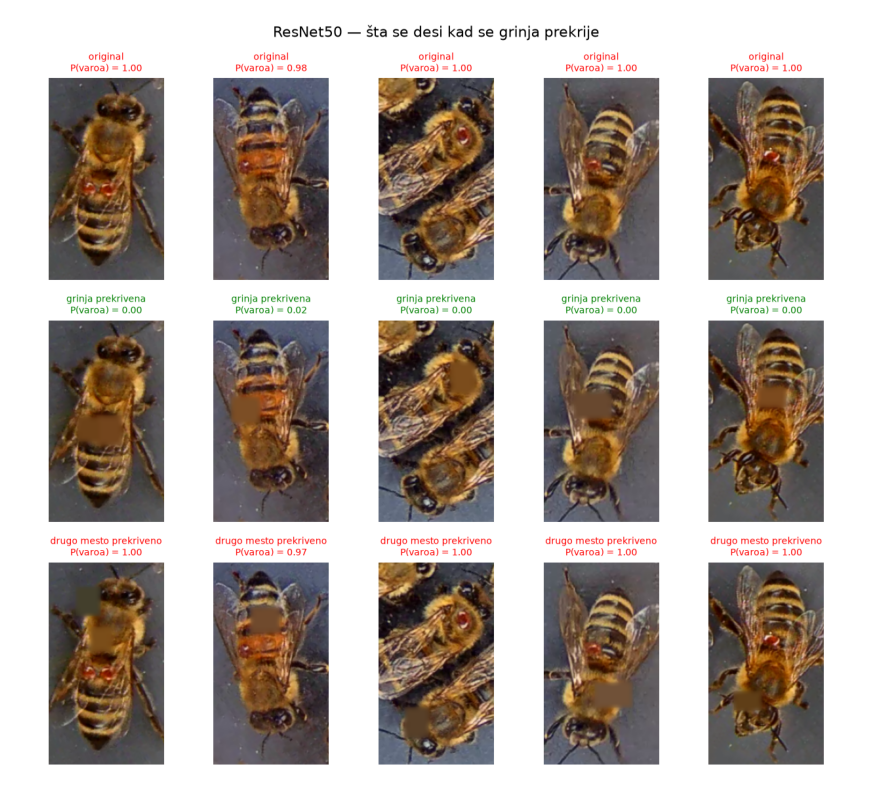

In [3]:
for run in runs:
    plt.figure(figsize=(11, 10)); plt.imshow(Image.open(RUNS / run / "masking_examples.png")); plt.axis("off"); plt.show()

## 3.2 Test 2 — samo pozadina

Modelu se daju samo uglovi slike (bez pčele). Pozadina je ista za obe klase, pa udeo
odgovora „varoa" mora biti sličan za uglove zdravih i zaraženih pčela.
Kod BeeImage modela, iz uglova je varoa „prepoznata" u 74% slučajeva.

In [4]:
pd.DataFrame({c["arch_display"]: c["background"] for c in checks.values()})

,EfficientNetB0,MobileNetV3-Large,ResNet50
udeo_varoa_uglovi_zdravih,0.0383,0.0278,0.0072
udeo_varoa_uglovi_zarazenih,0.0531,0.0361,0.0127


## 3.3 Test 3 — Grad-CAM

Grad-CAM pokazuje koji delovi slike su najviše doprineli odluci „varoa" (crveno = najviše).
Gornji red: grinja označena pravougaonikom iz `gt.csv`. Donji red: mapa pažnje modela.
„Pogodak" znači da je najjača tačka mape u pravougaoniku grinje.

In [5]:
pd.DataFrame({c["arch_display"]: c["gradcam_pointing"] for c in checks.values()})

,EfficientNetB0,MobileNetV3-Large,ResNet50
uzoraka,200.00,200.00,200.000
pogodak_u_grinju,0.87,0.87,0.465


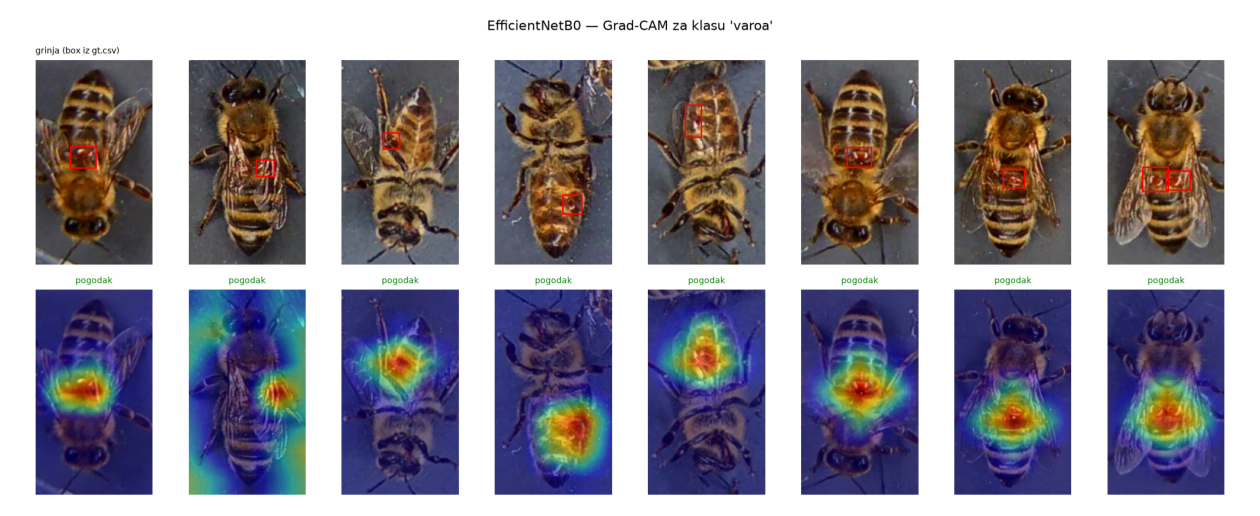

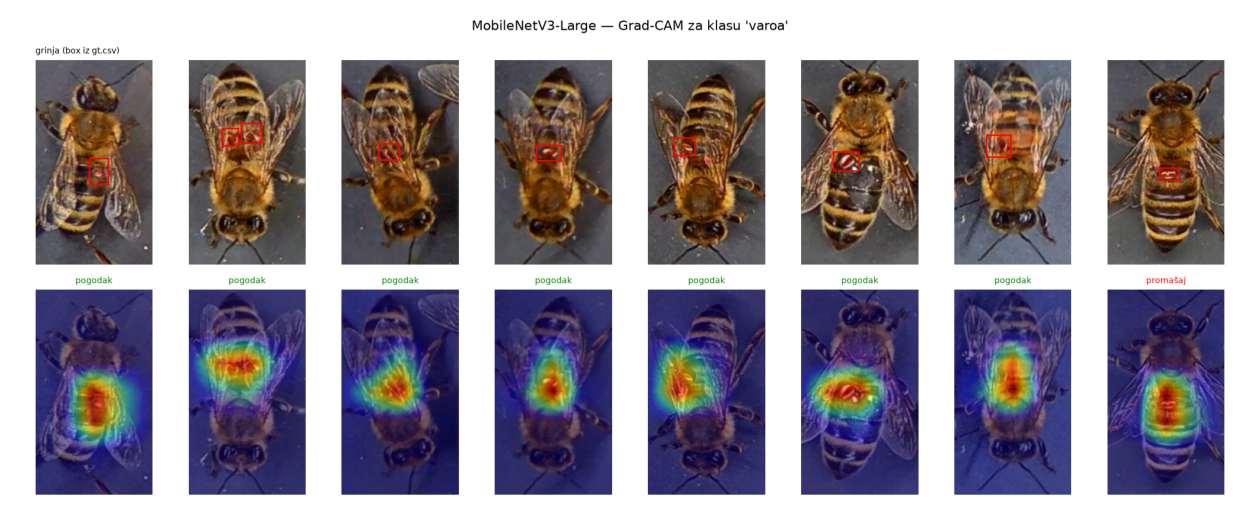

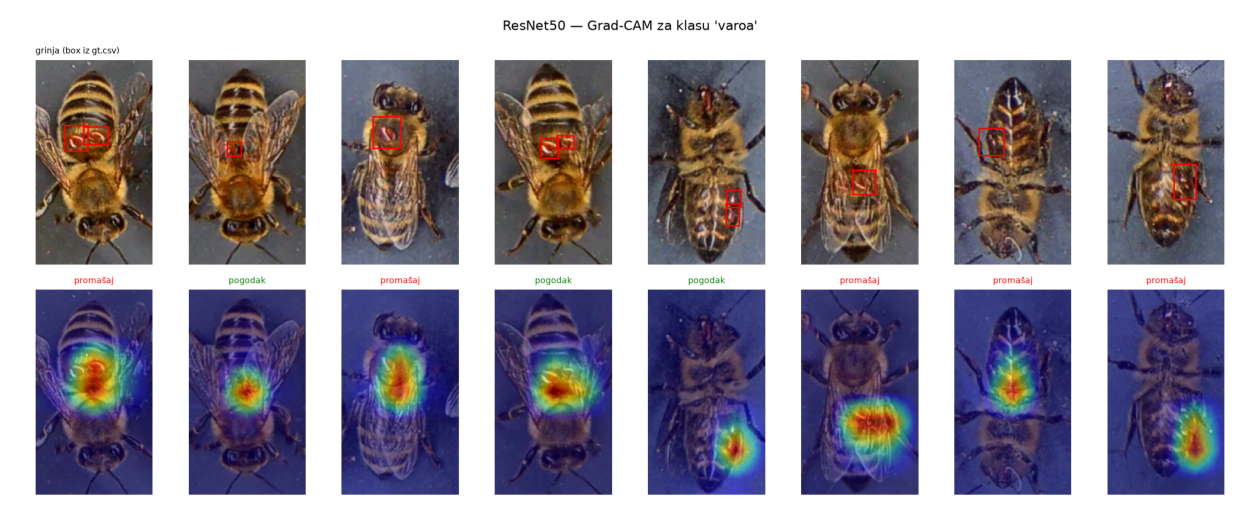

In [6]:
for run in runs:
    plt.figure(figsize=(16, 7)); plt.imshow(Image.open(RUNS / run / "gradcam.png")); plt.axis("off"); plt.show()

## 3.4 Test van skupa za trening

1. **BeeDataset** (7.490 slika) — druga kamera, druga zemlja, zelena podloga. Model ga nikad nije video.
2. **Terenske fotografije** (`data/field_photos/`) — fotografije pojedinačnih pčela sa bilo kojom
   pozadinom, uključujući onu koja je otkrila problem sa prvim modelom.

In [7]:
field = json.loads((RUNS / "field_test.json").read_text())
pd.DataFrame({v["arch_display"]: v.get("beedataset", {}) for v in field.values()})

,EfficientNetB0,MobileNetV3-Large,ResNet50
slika,7490.0000,7490.0000,7490.0000
sa_varoom,1266.0000,1266.0000,1266.0000
accuracy,0.8650,0.8999,0.8794
recall_varoa,0.2030,0.4755,0.3049
precision_varoa,0.9923,0.8750,0.9438
macro_f1,0.6310,0.7793,0.6965
roc_auc,0.9279,0.9488,0.8694


In [8]:
rows = []
for v in field.values():
    for r in v.get("field", {}).get("po_slici", []):
        rows.append({"model": v["arch_display"], **r})
pd.DataFrame(rows).pivot(index=["fajl", "prava_klasa"], columns="model", values="p_varoa")

,model,EfficientNetB0,MobileNetV3-Large,ResNet50
fajl,prava_klasa,,,
varoa/makro_pcela_na_sacu_2_grinje.jpg,varoa,0.9848,0.1723,0.9886
zdrava/pcela_na_cvetu.jpg,zdrava,0.0419,0.1065,0.0052


## 3.5 Isti test kroz pravi servis

Fotografija koja je otkrila problem, poslata kroz isti kod koji koristi aplikacija
(`service/inference.py`, ONNX model koji je trenutno u produkciji):

In [9]:
from service.inference import BeeHealthModel
served = BeeHealthModel(ROOT / "models" / "bee_health.onnx")
print("Model u servisu:", served.arch, "| klase:", served.classes)
for p in sorted((ROOT / "data" / "field_photos").glob("*/*")):
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}:
        print(f"{p.parent.name:6s} {p.name:40s} ->", served.predict(p.read_bytes()))

Model u servisu: ResNet50 | klase: ['zdrava', 'varoa']
varoa  makro_pcela_na_sacu_2_grinje.jpg         -> {'label': 'varoa', 'confidence': 0.9886, 'all_probs': {'zdrava': 0.0114, 'varoa': 0.9886}, 'model_version': 'bee_health'}
zdrava pcela_na_cvetu.jpg                       -> {'label': 'zdrava', 'confidence': 0.9948, 'all_probs': {'zdrava': 0.9948, 'varoa': 0.0052}, 'model_version': 'bee_health'}
